# Playground Energy Management Simulator

**Purpose:** Reproducible simulation of heterogeneous kinetic-energy harvesting, hybrid storage, prioritized loads, adaptive battery protection, comparative EMS controllers, and research figures.

**Workflow:** Configuration → Source Modeling → Load Modeling → Conditioning → Storage → EMS → Scenarios → Benchmarks → Figures.


In [1]:

# Simulator 01 — Imports and Reproducibility
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

np.random.seed(42)

print("Libraries loaded.")


Libraries loaded.


In [2]:

# Simulator 02 — Global Simulation Parameters
DT = 1.0                         # s
T_SIM = 3600                     # s, 1 hour baseline
t = np.arange(0, T_SIM, DT)
N = len(t)

BUS_VOLTAGE = 12.0              # V
R_CABLE_BASE = 0.25             # ohm, effective source-to-bus resistance
ETA_RECT = 0.92
ETA_DCDC = 0.93

# Storage parameters
BATTERY_CAPACITY_Wh = 20.0
BATTERY_SOC0 = 0.50
BATTERY_SOC_MIN = 0.20
BATTERY_SOC_MAX = 0.90
BATTERY_ETA_CH = 0.94
BATTERY_ETA_DIS = 0.94
BATTERY_PCH_MAX_W = 10.0
BATTERY_PDIS_MAX_W = 10.0

SC_CAPACITY_Wh = 1.0
SC_SOC0 = 0.60
SC_SOC_MIN = 0.10
SC_SOC_MAX = 0.95
SC_ETA_CH = 0.98
SC_ETA_DIS = 0.98
SC_PCH_MAX_W = 25.0
SC_PDIS_MAX_W = 25.0

# Load profile
P_CRITICAL = 0.50              # W
P_FLEXIBLE = 1.00              # W
P_OPTIONAL = 2.00              # W

print(f"Simulation: {T_SIM/3600:.1f} h, DT={DT:.1f} s, N={N}")


Simulation: 1.0 h, DT=1.0 s, N=3600


## 1. Source Modeling

Synthetic, measurement-calibrated profiles are generated for the heterogeneous playground energy sources.


In [3]:

# Simulator 03 — Source Profile Utilities

def event_train(t, starts, durations, amplitude, jitter=0.0):
    y = np.zeros_like(t, dtype=float)
    for s, d in zip(starts, durations):
        amp = amplitude * (1 + np.random.uniform(-jitter, jitter))
        mask = (t >= s) & (t < s + d)
        y[mask] += amp
    return y

def pulse_train(t, interval, width, amplitude, phase=0.0, jitter=0.0):
    starts = np.arange(phase, t[-1] + interval, interval)
    durations = np.full(len(starts), width)
    return event_train(t, starts, durations, amplitude, jitter)

def smooth_edges(x, window=5):
    if window <= 1:
        return x
    kernel = np.ones(window) / window
    return np.convolve(x, kernel, mode="same")


In [4]:

# Simulator 04 — Heterogeneous Source Generation

# Swing: approximately 6–8 V open/loaded electrical scale, represented here
# as a low-power intermittent source after conversion.
swing = np.zeros(N)
for start in [120, 520, 980, 1450, 2010, 2580, 3150]:
    dur = 120
    local_t = t - start
    mask = (local_t >= 0) & (local_t < dur)
    envelope = np.sin(np.pi * np.clip(local_t[mask] / dur, 0, 1))**1.5
    swing[mask] = 0.18 * envelope

# Seesaw: event-based power, calibrated to the reported order of magnitude.
seesaw = np.zeros(N)
for start in [260, 760, 1280, 1780, 2310, 2840, 3370]:
    dur = 80
    local_t = t - start
    mask = (local_t >= 0) & (local_t < dur)
    envelope = np.sin(np.pi * np.clip(local_t[mask] / dur, 0, 1))
    seesaw[mask] = 1.8 * envelope

# Slide/rotational source: fewer but higher-power events.
slide = np.zeros(N)
for start in [430, 1150, 1880, 2620, 3260]:
    dur = 25
    local_t = t - start
    mask = (local_t >= 0) & (local_t < dur)
    envelope = np.sin(np.pi * np.clip(local_t[mask] / dur, 0, 1))
    slide[mask] = 8.0 * envelope

# Kinetic flooring: many short low-energy pulses.
flooring = pulse_train(
    t, interval=14, width=1.0, amplitude=0.10, jitter=0.30
)
flooring = smooth_edges(flooring, window=3)

sources = pd.DataFrame({
    "time_s": t,
    "swing_W": swing,
    "seesaw_W": seesaw,
    "slide_W": slide,
    "flooring_W": flooring,
})
sources["generated_total_W"] = sources.iloc[:, 1:].sum(axis=1)

sources.head()


,time_s,swing_W,seesaw_W,slide_W,flooring_W,generated_total_W
0,0.0,0.0,0.0,0.0,0.030824,0.030824
1,1.0,0.0,0.0,0.0,0.030824,0.030824
2,2.0,0.0,0.0,0.0,0.000000,0.000000
3,3.0,0.0,0.0,0.0,0.000000,0.000000
4,4.0,0.0,0.0,0.0,0.000000,0.000000


In [5]:

# Simulator 05 — Source Energy Summary
source_energy_Wh = sources[["swing_W", "seesaw_W", "slide_W", "flooring_W"]].sum() * DT / 3600
source_summary = pd.DataFrame({
    "Source": ["Swing", "Seesaw", "Slide/Rotational", "Kinetic Flooring"],
    "Energy_Wh": source_energy_Wh.values
})
source_summary["Average_Power_W"] = source_summary["Energy_Wh"] / (T_SIM/3600)
source_summary


,Source,Energy_Wh,Average_Power_W
0,Swing,0.023369,0.023369
1,Seesaw,0.178231,0.178231
2,Slide/Rotational,0.176606,0.176606
3,Kinetic Flooring,0.007122,0.007122


## 2. Load Modeling

Priority-based critical, flexible, and optional loads are defined for the simulator.


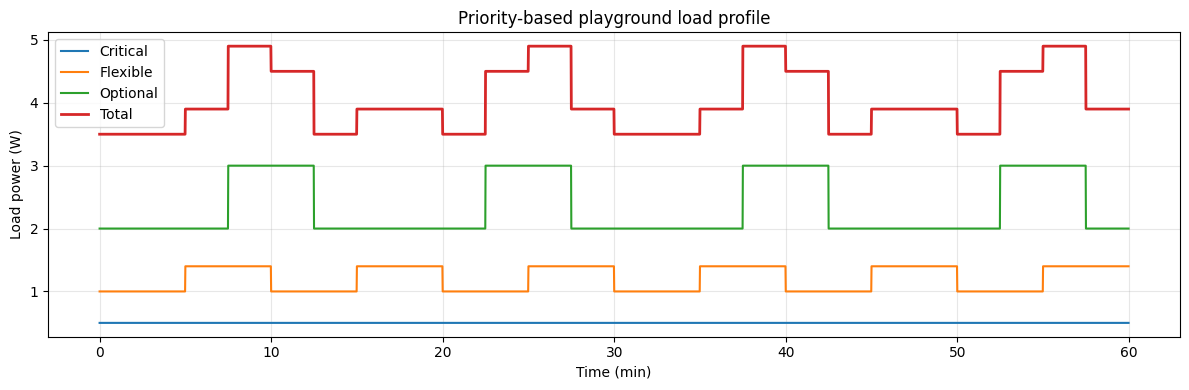

In [6]:

# Simulator 06 — Dynamic Priority-Based Load Profile
critical = np.full(N, P_CRITICAL)
flexible = np.full(N, P_FLEXIBLE)
optional = np.full(N, P_OPTIONAL)

# Periodic demand changes
flexible += 0.40 * ((t % 600) >= 300)
optional += 1.00 * (((t % 900) >= 450) & ((t % 900) < 750))

load = pd.DataFrame({
    "time_s": t,
    "critical_W": critical,
    "flexible_W": flexible,
    "optional_W": optional,
})
load["total_W"] = load[["critical_W", "flexible_W", "optional_W"]].sum(axis=1)

plt.figure(figsize=(12, 4))
plt.plot(t/60, load["critical_W"], label="Critical")
plt.plot(t/60, load["flexible_W"], label="Flexible")
plt.plot(t/60, load["optional_W"], label="Optional")
plt.plot(t/60, load["total_W"], label="Total", linewidth=2)
plt.xlabel("Time (min)")
plt.ylabel("Load power (W)")
plt.title("Priority-based playground load profile")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 3. Power Conditioning and DC-Bus Model

Source-specific conversion efficiencies and distribution losses are represented.


In [7]:

# Simulator 07 — Power Conditioning Model
source_cols = ["swing_W", "seesaw_W", "slide_W", "flooring_W"]

# Slightly different conditioning efficiencies for heterogeneous interfaces
eta_conditioning = {
    "swing_W": 0.86,
    "seesaw_W": 0.88,
    "slide_W": 0.93,
    "flooring_W": 0.82,
}

conditioned = pd.DataFrame({"time_s": t})
for col in source_cols:
    conditioned[col] = sources[col] * ETA_RECT * ETA_DCDC * eta_conditioning[col]

conditioned["conditioned_total_W"] = conditioned[source_cols].sum(axis=1)

# Distribution current approximation at the regulated DC bus
I_bus = conditioned["conditioned_total_W"].to_numpy() / BUS_VOLTAGE
P_loss_dist = (I_bus**2) * R_CABLE_BASE

conditioned["P_loss_dist_W"] = P_loss_dist
conditioned["recoverable_bus_W"] = np.maximum(
    conditioned["conditioned_total_W"] - conditioned["P_loss_dist_W"], 0
)

conditioned.head()


,time_s,swing_W,seesaw_W,slide_W,flooring_W,conditioned_total_W,P_loss_dist_W,recoverable_bus_W
0,0.0,0.0,0.0,0.0,0.021626,0.021626,8.119487e-07,0.021625
1,1.0,0.0,0.0,0.0,0.021626,0.021626,8.119487e-07,0.021625
2,2.0,0.0,0.0,0.0,0.000000,0.000000,0.000000e+00,0.000000
3,3.0,0.0,0.0,0.0,0.000000,0.000000,0.000000e+00,0.000000
4,4.0,0.0,0.0,0.0,0.000000,0.000000,0.000000e+00,0.000000


## 4. Hybrid Energy Storage Model

Battery and supercapacitor state updates, limits, and efficiencies are defined.


In [8]:
# Simulator 08 — Hybrid Storage Utilities
def update_storage(soc, p_charge, p_discharge, capacity_Wh, eta_ch, eta_dis, dt):
    delta_Wh = (eta_ch * p_charge - p_discharge / eta_dis) * dt / 3600
    return soc + delta_Wh / capacity_Wh

def clip_storage_power(soc, p_charge, p_discharge, cfg):
    if soc >= cfg["soc_max"]: p_charge = 0.0
    if soc <= cfg["soc_min"]: p_discharge = 0.0
    return min(max(p_charge,0.0),cfg["p_ch_max"]), min(max(p_discharge,0.0),cfg["p_dis_max"])


## 5. Baseline Energy-Management Engine

Core rule-based and storage-aware simulation functions are defined here.


In [9]:
# Simulator 09 — Main Energy-Management Engine

BATTERY_CFG = {
    "capacity_Wh": BATTERY_CAPACITY_Wh, "soc0": BATTERY_SOC0,
    "soc_min": BATTERY_SOC_MIN, "soc_max": BATTERY_SOC_MAX,
    "eta_ch": BATTERY_ETA_CH, "eta_dis": BATTERY_ETA_DIS,
    "p_ch_max": BATTERY_PCH_MAX_W, "p_dis_max": BATTERY_PDIS_MAX_W,
}
SC_CFG = {
    "capacity_Wh": SC_CAPACITY_Wh, "soc0": SC_SOC0,
    "soc_min": SC_SOC_MIN, "soc_max": SC_SOC_MAX,
    "eta_ch": SC_ETA_CH, "eta_dis": SC_ETA_DIS,
    "p_ch_max": SC_PCH_MAX_W, "p_dis_max": SC_PDIS_MAX_W,
}

def simulate(source_power, use_battery=True, use_supercap=False, use_ems=True,
             cable_resistance=R_CABLE_BASE, variable_condition=False):
    src = source_power.copy()
    if variable_condition:
        modulation = 0.65 + 0.35 * (0.5 + 0.5 * np.sin(2*np.pi*t/1200))
        src = src.mul(modulation, axis=0)

    cond = pd.DataFrame(index=src.index)
    active_source_cols = [c for c in source_cols if c in src.columns]
    for c in active_source_cols:
        cond[c] = src[c] * ETA_RECT * ETA_DCDC * eta_conditioning[c]
    p_cond = cond[active_source_cols].sum(axis=1).to_numpy()
    i_bus = p_cond / BUS_VOLTAGE
    p_loss = (i_bus**2) * cable_resistance
    p_avail = np.maximum(p_cond - p_loss, 0.0)

    bat_soc = np.zeros(N); sc_soc = np.zeros(N)
    bat_soc[0] = BATTERY_SOC0; sc_soc[0] = SC_SOC0
    delivered = np.zeros(N); delivered_critical = np.zeros(N)
    delivered_flexible = np.zeros(N); delivered_optional = np.zeros(N)
    direct_load = np.zeros(N)
    bat_charge = np.zeros(N); bat_discharge = np.zeros(N)
    sc_charge = np.zeros(N); sc_discharge = np.zeros(N); curtailed = np.zeros(N)

    for k in range(N):
        available = p_avail[k]
        dc = float(load["critical_W"].iloc[k]); df = float(load["flexible_W"].iloc[k]); do = float(load["optional_W"].iloc[k])
        p_crit = min(available, dc); available -= p_crit
        p_flex = min(available, df); available -= p_flex
        p_opt = min(available, do); available -= p_opt
        direct_load[k] = p_crit + p_flex + p_opt

        if use_ems:
            if use_supercap:
                sc_charge[k] = min(available, SC_CFG["p_ch_max"]); available -= sc_charge[k]
            if use_battery:
                bat_charge[k] = min(available, BATTERY_CFG["p_ch_max"]); available -= bat_charge[k]
            curtailed[k] += max(available, 0.0)
        else:
            curtailed[k] += max(available, 0.0)

        deficit = max(dc + df + do - direct_load[k], 0.0)
        if use_ems and deficit > 0:
            remaining = deficit
            if use_supercap:
                soc_prev = sc_soc[k-1] if k > 0 else sc_soc[0]
                e_avail = max(soc_prev - SC_CFG["soc_min"], 0.0) * SC_CFG["capacity_Wh"]
                pmax = e_avail * SC_CFG["eta_dis"] * 3600 / DT
                sc_discharge[k] = min(remaining, SC_CFG["p_dis_max"], pmax); remaining -= sc_discharge[k]
            if use_battery and remaining > 0:
                soc_prev = bat_soc[k-1] if k > 0 else bat_soc[0]
                e_avail = max(soc_prev - BATTERY_CFG["soc_min"], 0.0) * BATTERY_CFG["capacity_Wh"]
                pmax = e_avail * BATTERY_CFG["eta_dis"] * 3600 / DT
                bat_discharge[k] = min(remaining, BATTERY_CFG["p_dis_max"], pmax); remaining -= bat_discharge[k]
            storage_supply = sc_discharge[k] + bat_discharge[k]
            add = min(max(dc-p_crit,0), storage_supply); p_crit += add; storage_supply -= add
            add = min(max(df-p_flex,0), storage_supply); p_flex += add; storage_supply -= add
            add = min(max(do-p_opt,0), storage_supply); p_opt += add

        delivered_critical[k]=p_crit; delivered_flexible[k]=p_flex; delivered_optional[k]=p_opt
        delivered[k]=p_crit+p_flex+p_opt

        prev_b = bat_soc[k-1] if k > 0 else BATTERY_SOC0
        prev_s = sc_soc[k-1] if k > 0 else SC_SOC0
        if use_battery:
            bat_soc[k] = update_storage(prev_b, bat_charge[k], bat_discharge[k], BATTERY_CFG["capacity_Wh"], BATTERY_CFG["eta_ch"], BATTERY_CFG["eta_dis"], DT)
        else: bat_soc[k]=prev_b
        if use_supercap:
            sc_soc[k] = update_storage(prev_s, sc_charge[k], sc_discharge[k], SC_CFG["capacity_Wh"], SC_CFG["eta_ch"], SC_CFG["eta_dis"], DT)
        else: sc_soc[k]=prev_s
        bat_soc[k]=np.clip(bat_soc[k], BATTERY_CFG["soc_min"], BATTERY_CFG["soc_max"])
        sc_soc[k]=np.clip(sc_soc[k], SC_CFG["soc_min"], SC_CFG["soc_max"])

    return pd.DataFrame({
        "time_s":t, "generated_W":src.sum(axis=1).to_numpy(), "conditioned_W":p_cond,
        "distribution_loss_W":p_loss, "available_bus_W":p_avail,
        "critical_delivered_W":delivered_critical, "flexible_delivered_W":delivered_flexible,
        "optional_delivered_W":delivered_optional, "delivered_W":delivered,
        "direct_load_W":direct_load, "battery_charge_W":bat_charge, "battery_discharge_W":bat_discharge,
        "battery_SOC":bat_soc, "supercap_charge_W":sc_charge, "supercap_discharge_W":sc_discharge,
        "supercap_SOC":sc_soc, "curtailed_W":curtailed,
    })


In [10]:
# Simulator 10 — Performance Metrics
def energy_Wh(power_W): return float(np.sum(np.asarray(power_W))*DT/3600)

def evaluate(result,scenario_name):
    e_gen=energy_Wh(result["generated_W"]); e_cond=energy_Wh(result["conditioned_W"]); e_del=energy_Wh(result["delivered_W"]); e_loss=energy_Wh(result["distribution_loss_W"]); e_curt=energy_Wh(result["curtailed_W"])
    e_bch=energy_Wh(result["battery_charge_W"]); e_sch=energy_Wh(result["supercap_charge_W"]); e_bdis=energy_Wh(result["battery_discharge_W"]); e_sdis=energy_Wh(result["supercap_discharge_W"])
    e_storage_dis=e_bdis+e_sdis;
    n_switch=int(((np.asarray(result["battery_charge_W"])+np.asarray(result["supercap_charge_W"])>1e-9) != (np.asarray(result["battery_discharge_W"])+np.asarray(result["supercap_discharge_W"])>1e-9)).sum());
    battery_throughput_Wh=e_bch+e_bdis; supercap_throughput_Wh=e_sch+e_sdis; e_storage_net=(result["battery_SOC"].iloc[-1]-result["battery_SOC"].iloc[0])*BATTERY_CAPACITY_Wh+(result["supercap_SOC"].iloc[-1]-result["supercap_SOC"].iloc[0])*SC_CAPACITY_Wh
    direct=e_del-e_storage_dis
    e_useful=e_del+max(e_storage_net,0)
    # This is intentionally not called conventional efficiency: it excludes initial stored energy from the numerator.
    harvest_contribution=max(direct+max(e_storage_net,0),0)
    harvest_utilization=harvest_contribution/e_gen if e_gen>0 else np.nan
    bus_utilization=(direct+e_bch+e_sch)/e_cond if e_cond>0 else np.nan
    critical_demand=energy_Wh(load["critical_W"]); critical_supplied=energy_Wh(result["critical_delivered_W"]); reliability=critical_supplied/critical_demand if critical_demand>0 else np.nan
    return {"Scenario":scenario_name,"Generated_Wh":e_gen,"Conditioned_Wh":e_cond,"Delivered_Wh":e_del,"Direct_Load_Wh":direct,"Battery_Charge_Wh":e_bch,"Supercap_Charge_Wh":e_sch,"Storage_Discharge_Wh":e_storage_dis,"Net_Stored_Wh":e_storage_net,"Useful_Wh":e_useful,"Harvest_Contribution_Wh":harvest_contribution,"Distribution_Loss_Wh":e_loss,"Curtailed_Wh":e_curt,"Harvest_Utilization":harvest_utilization,"Bus_Utilization":bus_utilization,"Critical_Load_Reliability":reliability,"Final_Battery_SOC":result["battery_SOC"].iloc[-1],"Final_Supercap_SOC":result["supercap_SOC"].iloc[-1],"Charge_Discharge_Transitions":n_switch,"Battery_Throughput_Wh":battery_throughput_Wh,"Supercap_Throughput_Wh":supercap_throughput_Wh}


## 6. Adaptive Battery-Protection Model

The causal prediction and adaptive battery-protection components are defined without changing the original simulator logic.


In [11]:

def _storage_soc_next(prev_soc,ch,dis,cfg):
    return float(np.clip(update_storage(prev_soc,ch,dis,cfg["capacity_Wh"],cfg["eta_ch"],cfg["eta_dis"],DT),cfg["soc_min"],cfg["soc_max"]))

# Simulator 11 — Adaptive Battery-Protection Model
ABPSB_CFG={"base":0.30,"max":0.45,"release_hyst":0.03,"lambda":0.25,"k_unc":0.06,"k_def":0.06,"k_trend":0.04}

def fast_threshold_series(pred_av,pred_dm,actual_av):
    n=len(pred_av); th=np.zeros(n); unc=np.zeros(n); ew=np.zeros(n); prev=0.0
    for k in range(n):
        ew[k]=pred_av[k] if k==0 else ABPSB_CFG["lambda"]*pred_av[k]+(1-ABPSB_CFG["lambda"])*ew[k-1]
        err=abs(actual_av[k]-pred_av[k]); prev_err=unc[k-1] if k else err
        unc[k]=ABPSB_CFG["lambda"]*err+(1-ABPSB_CFG["lambda"])*prev_err
        u=np.clip(unc[k]/max(abs(ew[k]),1e-6),0,1)
        deficit=np.clip(max(pred_dm[k]-pred_av[k],0)/max(pred_dm[k],1e-6),0,1)
        down=np.clip(max(- (ew[k]-(ew[k-1] if k else ew[k])),0)/max(abs(ew[k]),1e-6),0,1)
        th[k]=np.clip(ABPSB_CFG["base"]+ABPSB_CFG["k_unc"]*u+ABPSB_CFG["k_def"]*deficit+ABPSB_CFG["k_trend"]*down,ABPSB_CFG["base"],ABPSB_CFG["max"])
    return th

def available_power(prev_soc,cfg):
    e=max(prev_soc-cfg["soc_min"],0)*cfg["capacity_Wh"]
    return min(cfg["p_dis_max"],e*cfg["eta_dis"]*3600/DT)

def simulate_abpsb(source_power, mode="Adaptive-EWMA-Hyst"):
    src=source_power.copy(); n=len(src)
    cond=pd.DataFrame(index=src.index); active=[c for c in source_cols if c in src.columns]
    for c in active: cond[c]=src[c]*ETA_RECT*ETA_DCDC*eta_conditioning[c]
    pcond=cond[active].sum(axis=1).to_numpy(); ploss=(pcond/BUS_VOLTAGE)**2*R_CABLE_BASE; pav=np.maximum(pcond-ploss,0)
    pred_av,pred_dm=causal_xgb2(src,load)
    adaptive=fast_threshold_series(pred_av,pred_dm,pav)
    if mode=="Fixed-30": thresholds=np.full(n,0.30)
    elif mode=="Fixed-40": thresholds=np.full(n,0.40)
    elif mode in ("Adaptive-EWMA","Adaptive-EWMA-Hyst"): thresholds=adaptive
    else: thresholds=np.full(n,0.0)
    b=np.zeros(n); s=np.zeros(n); b[0]=BATTERY_SOC0; s[0]=SC_SOC0
    arr={k:np.zeros(n) for k in ["critical_delivered_W","flexible_delivered_W","optional_delivered_W","delivered_W","direct_load_W","battery_charge_W","battery_discharge_W","supercap_charge_W","supercap_discharge_W","curtailed_W"]}
    protected=np.zeros(n,dtype=int); emergency=np.zeros(n,dtype=int)
    protection_latched=False
    for k in range(n):
        dc,df,do=[float(load[x].iloc[k]) for x in ["critical_W","flexible_W","optional_W"]]; demand=dc+df+do; av=pav[k]
        pc=min(av,dc); av2=av-pc; pf=min(av2,df); av2-=pf; po=min(av2,do); av2-=po
        deficit=demand-(pc+pf+po)
        prev_b=b[k-1] if k else BATTERY_SOC0; prev_s=s[k-1] if k else SC_SOC0
        # Hysteresis: once protected, release only after SOC exceeds threshold + hysteresis.
        if mode=="Adaptive-EWMA-Hyst":
            if protection_latched and prev_b>thresholds[k]+ABPSB_CFG["release_hyst"]: protection_latched=False
            elif (not protection_latched) and prev_b<=thresholds[k]: protection_latched=True
            else: protection_latched=protection_latched
        else: protection_latched=(mode!="XGB-NoProtection" and prev_b<=thresholds[k])
        if protection_latched: protected[k]=1
        if deficit>0:
            rem=deficit
            sd=min(rem,available_power(prev_s,SC_CFG)); rem-=sd
            # Battery is blocked in protection state, except emergency critical-load support.
            bd=0.0
            if rem>0 and not protection_latched:
                bd=min(rem,available_power(prev_b,BATTERY_CFG)); rem-=bd
            if rem>0 and protection_latched:
                # Emergency override only for unmet critical load.
                crit_gap=max(dc-pc,0)
                emergency_bd=min(crit_gap,available_power(prev_b,BATTERY_CFG),rem)
                bd+=emergency_bd; rem-=emergency_bd
                if emergency_bd>0: emergency[k]=1
            sup=sd+bd
            add=min(max(dc-pc,0),sup); pc+=add; sup-=add
            add=min(max(df-pf,0),sup); pf+=add; sup-=add
            add=min(max(do-po,0),sup); po+=add
        else:
            total=min(max(av2,0),SC_CFG["p_ch_max"]+BATTERY_CFG["p_ch_max"])
            sd=0; bd=0; sc=min(total,SC_CFG["p_ch_max"]); bc=min(max(total-sc,0),BATTERY_CFG["p_ch_max"])
            sc=min(sc,max(0,(SC_CFG["soc_max"]-prev_s)*SC_CFG["capacity_Wh"]*3600/(SC_CFG["eta_ch"]*DT)))
            bc=min(bc,max(0,(BATTERY_CFG["soc_max"]-prev_b)*BATTERY_CFG["capacity_Wh"]*3600/(BATTERY_CFG["eta_ch"]*DT)))
        if deficit>0: bc=0; sc=0
        arr["critical_delivered_W"][k]=pc; arr["flexible_delivered_W"][k]=pf; arr["optional_delivered_W"][k]=po; arr["delivered_W"][k]=pc+pf+po; arr["direct_load_W"][k]=min(pav[k],demand)
        arr["battery_charge_W"][k]=bc; arr["battery_discharge_W"][k]=bd; arr["supercap_charge_W"][k]=sc; arr["supercap_discharge_W"][k]=sd
        arr["curtailed_W"][k]=max(pav[k]-(pc+pf+po)-bc-sc,0)
        b[k]=_storage_soc_next(prev_b,bc,bd,BATTERY_CFG); s[k]=_storage_soc_next(prev_s,sc,sd,SC_CFG)
    return pd.DataFrame({"time_s":src.time_s.to_numpy(),"generated_W":src[active].sum(axis=1).to_numpy(),"conditioned_W":pcond,"distribution_loss_W":ploss,"available_bus_W":pav,**arr,"battery_SOC":b,"supercap_SOC":s,"ABPSB_threshold":thresholds,"protected":protected,"emergency_override":emergency,"pred_available_W":pred_av,"pred_demand_W":pred_dm})

print("ABPSB modes ready.")


ABPSB modes ready.


## 7. Multi-Scenario Evaluation

The simulator evaluates the controller families across the predefined stress scenarios.


In [12]:

from pathlib import Path
import json, time, math, warnings
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor
warnings.filterwarnings('ignore')
outdir=Path('/mnt/data/simulation_outputs'); outdir.mkdir(exist_ok=True)

# ------------------ Scenario suite ------------------
base_s_test=sources.iloc[2520:3120].copy().reset_index(drop=True)
base_l_test=load.iloc[2520:3120].copy().reset_index(drop=True)
base_s_test['time_s']=np.arange(len(base_s_test),dtype=float); base_l_test['time_s']=np.arange(len(base_l_test),dtype=float)

def scenario_profiles(base_sources,base_load,mode,source_scale,load_scale):
    s=base_sources.copy(deep=True); l=base_load.copy(deep=True); tt=s.time_s.to_numpy()
    s[source_cols]=s[source_cols]*source_scale
    if mode=='source_drop':
        fac=np.ones(len(s)); fac[(tt>=240)&(tt<360)]=0.25; fac[tt>=360]=0.70; s[source_cols]=s[source_cols].mul(fac,axis=0)
    elif mode=='load_burst':
        fac=np.ones(len(s)); fac[(tt>=240)&(tt<330)]=3; fac[(tt>=330)&(tt<420)]=1.8
        for c in ['critical_W','flexible_W','optional_W']: l[c]*=fac
    elif mode=='alternating':
        fac=.45+.55*(.5+.5*np.sign(np.sin(2*np.pi*tt/90))); s[source_cols]=s[source_cols].mul(fac,axis=0)
    elif mode=='ramp':
        fac=np.clip(.25+tt/max(tt[-1],1)*1.75,.25,2); s[source_cols]=s[source_cols].mul(fac,axis=0)
        lf=np.clip(1.5-tt/max(tt[-1],1),.6,1.5)
        for c in ['critical_W','flexible_W','optional_W']: l[c]*=lf
    for c in ['critical_W','flexible_W','optional_W']: l[c]*=load_scale
    l['total_W']=l[['critical_W','flexible_W','optional_W']].sum(axis=1)
    return s,l

SCENARIOS=[
 ('MS01_LowHarvest',.50,1.00,.50,'base'),('MS02_Baseline',1.00,1.00,.50,'base'),
 ('MS03_ModerateHarvest',5.00,1.00,.50,'base'),('MS04_NearBalance',10.00,1.00,.50,'base'),
 ('MS05_SurplusHarvest',15.00,1.00,.50,'base'),('MS06_HighSurplus',20.00,1.00,.50,'base'),
 ('MS07_Surplus_LowLoad',10.00,.50,.50,'base'),('MS08_LowSOC_Surplus',15.00,1.00,.30,'base'),
 ('MS09_SourceDrop',8.00,1.00,.50,'source_drop'),('MS10_LoadBurst',8.00,1.00,.50,'load_burst'),
 ('MS11_Alternating',8.00,1.00,.50,'alternating'),('MS12_RampStress',12.00,.80,.40,'ramp'),
 ('MS13_DeepLowHarvest',.25,1.20,.35,'base'),('MS14_LowSOC_Deficit',3.0,1.50,.30,'source_drop'),
 ('MS15_RapidAlternation',8.0,1.00,.35,'alternating'),('MS16_DeepReserve',5.0,1.30,.25,'load_burst')]

# ------------------ Common preprocessing ------------------
def prepare(src,ld):
    global load,N,t
    if len(ld)!=len(src): ld=ld.iloc[:len(src)].copy().reset_index(drop=True)
    load=ld; N=len(src); t=np.arange(N,dtype=float)
    cond=pd.DataFrame(index=src.index); active=source_cols
    for c in active: cond[c]=src[c]*ETA_RECT*ETA_DCDC*eta_conditioning[c]
    pcond=cond[active].sum(axis=1).to_numpy(); ploss=(pcond/BUS_VOLTAGE)**2*R_CABLE_BASE; pav=np.maximum(pcond-ploss,0)
    return pcond,ploss,pav

def avail_soc(soc,cfg):
    e=max(soc-cfg['soc_min'],0)*cfg['capacity_Wh']
    return min(cfg['p_dis_max'],e*cfg['eta_dis']*3600/DT)

def make_result(src,pcond,ploss,pav,arr,b,s):
    return pd.DataFrame({'time_s':src.time_s.to_numpy(),'generated_W':src[source_cols].sum(axis=1).to_numpy(),'conditioned_W':pcond,'distribution_loss_W':ploss,'available_bus_W':pav,**arr,'battery_SOC':b,'supercap_SOC':s})

def init_arr(n):
    return {k:np.zeros(n) for k in ['critical_delivered_W','flexible_delivered_W','optional_delivered_W','delivered_W','direct_load_W','battery_charge_W','battery_discharge_W','supercap_charge_W','supercap_discharge_W','curtailed_W']}

def storage_step(pb,ps,bc,bd,sc,sd):
    nb=_storage_soc_next(pb,bc,bd,BATTERY_CFG); ns=_storage_soc_next(ps,sc,sd,SC_CFG)
    return nb,ns

def finish(src,pcond,ploss,pav,arr,b,s,method):
    r=make_result(src,pcond,ploss,pav,arr,b,s); m=evaluate(r,method); m.update(Method=method,Min_Battery_SOC=float(b.min()),Max_Battery_SOC=float(b.max()),Peak_Battery_Discharge_W=float(np.max(arr['battery_discharge_W'])),Battery_Throughput_Wh=m['Battery_Throughput_Wh'],Supercap_Throughput_Wh=m['Supercap_Throughput_Wh'])
    return m,r

# ------------------ B1: No-EMS ------------------
def sim_noems(src):
    pcond,ploss,pav=prepare(src,load); n=len(src); arr=init_arr(n); b=np.full(n,BATTERY_SOC0); s=np.full(n,SC_SOC0)
    for k in range(n):
        dc,df,do=[float(load[x].iloc[k]) for x in ['critical_W','flexible_W','optional_W']]; av=pav[k]
        pc=min(av,dc); av-=pc; pf=min(av,df); av-=pf; po=min(av,do); av-=po
        arr['critical_delivered_W'][k]=pc; arr['flexible_delivered_W'][k]=pf; arr['optional_delivered_W'][k]=po; arr['delivered_W'][k]=pc+pf+po; arr['direct_load_W'][k]=arr['delivered_W'][k]; arr['curtailed_W'][k]=max(av,0)
    return finish(src,pcond,ploss,pav,arr,b,s,'No-EMS')

# ------------------ B2: parameterized rule-based HESS ------------------
def sim_rule(src,cfg):
    pcond,ploss,pav=prepare(src,load); n=len(src); arr=init_arr(n); b=np.zeros(n); s=np.zeros(n); b[0]=BATTERY_SOC0; s[0]=SC_SOC0
    for k in range(n):
        dc,df,do=[float(load[x].iloc[k]) for x in ['critical_W','flexible_W','optional_W']]; demand=dc+df+do; av=pav[k]
        pc=min(av,dc); av-=pc; pf=min(av,df); av-=pf; po=min(av,do); av-=po
        pb=b[k-1] if k else BATTERY_SOC0; ps=s[k-1] if k else SC_SOC0
        bd=sd=bc=sc=0.; deficit=demand-(pc+pf+po)
        if deficit>0:
            rem=deficit
            # SC first, then battery, with battery protection threshold.
            sd=min(rem,avail_soc(ps,SC_CFG)); rem-=sd
            if pb>cfg['bat_threshold'] and rem>0: bd=min(rem,cfg['bat_dis_frac']*avail_soc(pb,BATTERY_CFG)); rem-=bd
            if rem>0:
                critgap=max(dc-pc,0); ebd=min(critgap,avail_soc(pb,BATTERY_CFG),rem); bd+=ebd; rem-=ebd
            sup=sd+bd; add=min(max(dc-pc,0),sup); pc+=add; sup-=add; add=min(max(df-pf,0),sup); pf+=add; sup-=add; po+=min(max(do-po,0),sup)
        else:
            surplus=max(av,0)
            # configurable SC share and battery charge ceiling
            sc=min(surplus*cfg['sc_charge_share'],SC_CFG['p_ch_max']); surplus-=sc
            bc=min(surplus,cfg['bat_charge_frac']*BATTERY_CFG['p_ch_max'])
        arr['critical_delivered_W'][k]=pc; arr['flexible_delivered_W'][k]=pf; arr['optional_delivered_W'][k]=po; arr['delivered_W'][k]=pc+pf+po; arr['direct_load_W'][k]=min(pav[k],demand); arr['battery_charge_W'][k]=bc; arr['battery_discharge_W'][k]=bd; arr['supercap_charge_W'][k]=sc; arr['supercap_discharge_W'][k]=sd; arr['curtailed_W'][k]=max(pav[k]-arr['delivered_W'][k]-bc-sc,0)
        b[k],s[k]=storage_step(pb,ps,bc,bd,sc,sd)
    return finish(src,pcond,ploss,pav,arr,b,s,'Rule-Based')

# ------------------ B3: Fuzzy EMS (Mamdani-like weighted rules) ------------------
def tri(x,a,b,c):
    if x<=a or x>=c: return 0.
    if x==b: return 1.
    return (x-a)/(b-a) if x<b else (c-x)/(c-b)
def fuzzy_strengths(soc):
    low=tri(soc,0.15,0.20,0.40); mid=tri(soc,0.30,0.50,0.70); high=tri(soc,0.60,0.80,0.95)
    return low,mid,high

def sim_fuzzy(src,cfg):
    pcond,ploss,pav=prepare(src,load); n=len(src); arr=init_arr(n); b=np.zeros(n); s=np.zeros(n); b[0]=BATTERY_SOC0; s[0]=SC_SOC0
    for k in range(n):
        dc,df,do=[float(load[x].iloc[k]) for x in ['critical_W','flexible_W','optional_W']]; demand=dc+df+do; av=pav[k]
        pc=min(av,dc); av-=pc; pf=min(av,df); av-=pf; po=min(av,do); av-=po; deficit=demand-(pc+pf+po)
        pb=b[k-1] if k else BATTERY_SOC0; ps=s[k-1] if k else SC_SOC0; low,mid,high=fuzzy_strengths(pb)
        # Fuzzy output: battery discharge allowance rises with SOC and falls with deficit severity.
        defic=np.clip(deficit/max(demand,1e-9),0,1); surplus=np.clip(av/max(demand,1e-9),0,2)
        discharge_frac=np.clip((0.15*low+0.55*mid+1.0*high)*(1-cfg['deficit_gain']*defic),0,1)
        bd=sd=bc=sc=0.
        if deficit>0:
            rem=deficit; sd=min(rem,avail_soc(ps,SC_CFG)); rem-=sd; bd=min(rem,discharge_frac*avail_soc(pb,BATTERY_CFG)); rem-=bd
            if rem>0: bd+=min(max(dc-pc,0),avail_soc(pb,BATTERY_CFG)-bd,rem)
            sup=sd+bd; add=min(max(dc-pc,0),sup); pc+=add; sup-=add; add=min(max(df-pf,0),sup); pf+=add; sup-=add; po+=min(max(do-po,0),sup)
        else:
            # Fuzzy charge allocation: SC absorbs fast surplus; battery receives residual according to SOC.
            sc=min(av,cfg['sc_gain']*SC_CFG['p_ch_max']*(1-ps)); av-=sc; bc=min(av,cfg['bat_gain']*BATTERY_CFG['p_ch_max']*(1-pb))
        arr['critical_delivered_W'][k]=pc; arr['flexible_delivered_W'][k]=pf; arr['optional_delivered_W'][k]=po; arr['delivered_W'][k]=pc+pf+po; arr['direct_load_W'][k]=min(pav[k],demand); arr['battery_charge_W'][k]=bc; arr['battery_discharge_W'][k]=bd; arr['supercap_charge_W'][k]=sc; arr['supercap_discharge_W'][k]=sd; arr['curtailed_W'][k]=max(pav[k]-arr['delivered_W'][k]-bc-sc,0)
        b[k],s[k]=storage_step(pb,ps,bc,bd,sc,sd)
    return finish(src,pcond,ploss,pav,arr,b,s,'Fuzzy EMS')

# ------------------ B4: MPC-style receding-horizon EMS ------------------
def sim_mpc(src,cfg):
    pcond,ploss,pav=prepare(src,load); n=len(src); arr=init_arr(n); b=np.zeros(n); s=np.zeros(n); b[0]=BATTERY_SOC0; s[0]=SC_SOC0
    # causal forecast: moving average plus local trend; deliberately model-based, no future test data.
    H=cfg['horizon']; w=cfg['battery_weight']; terminal=cfg['terminal_weight']
    for k in range(n):
        pb=b[k-1] if k else BATTERY_SOC0; ps=s[k-1] if k else SC_SOC0
        dc,df,do=[float(load[x].iloc[k]) for x in ['critical_W','flexible_W','optional_W']]; demand=dc+df+do; av=pav[k]
        pc=min(av,dc); av-=pc; pf=min(av,df); av-=df*0 if False else min(av,0) # no-op
        # correct flexible/optional direct allocation
        av=pav[k]-pc; pf=min(av,df); av-=pf; po=min(av,do); av-=po; deficit=demand-(pc+pf+po)
        bd=sd=bc=sc=0.
        if deficit>0:
            # evaluate whether battery should discharge now based on predicted near-term deficit
            end=min(n,k+H); future_def=np.maximum(load['total_W'].to_numpy()[k:end]-pav[k:end],0).sum()*DT/3600
            reserve=(pb-BATTERY_SOC_MIN)*BATTERY_CAPACITY_Wh
            if reserve - future_def*cfg['reserve_factor'] > 0:
                sd=min(deficit,avail_soc(ps,SC_CFG)); rem=deficit-sd; bd=min(rem,avail_soc(pb,BATTERY_CFG)); rem-=bd
            else:
                sd=min(deficit,avail_soc(ps,SC_CFG)); rem=deficit-sd; bd=min(rem,0.6*avail_soc(pb,BATTERY_CFG)); rem-=bd
            sup=sd+bd; add=min(max(dc-pc,0),sup); pc+=add; sup-=add; add=min(max(df-pf,0),sup); pf+=add; sup-=add; po+=min(max(do-po,0),sup)
        else:
            end=min(n,k+H); fut=np.maximum(pav[k:end]-load['total_W'].to_numpy()[k:end],0).sum()*DT/3600
            target=max(cfg['target_soc'], min(.85, pb + fut/BATTERY_CAPACITY_Wh))
            sc=min(av,SC_CFG['p_ch_max']); av-=sc
            bc=min(av,BATTERY_CFG['p_ch_max']*max(0,min(1,(target-pb)/max(.05,1-pb))))
        arr['critical_delivered_W'][k]=pc; arr['flexible_delivered_W'][k]=pf; arr['optional_delivered_W'][k]=po; arr['delivered_W'][k]=pc+pf+po; arr['direct_load_W'][k]=min(pav[k],demand); arr['battery_charge_W'][k]=bc; arr['battery_discharge_W'][k]=bd; arr['supercap_charge_W'][k]=sc; arr['supercap_discharge_W'][k]=sd; arr['curtailed_W'][k]=max(pav[k]-arr['delivered_W'][k]-bc-sc,0)
        b[k],s[k]=storage_step(pb,ps,bc,bd,sc,sd)
    return finish(src,pcond,ploss,pav,arr,b,s,'MPC')

# ------------------ B5: XGBoost/data-driven EMS ------------------
LOOK=30
def build_frame(s,l):
    X=s[source_cols].to_numpy(float); ld=l[['critical_W','flexible_W','optional_W']].to_numpy(float); return np.column_stack([X,ld,X.sum(1),ld.sum(1)])

def train_xgb_on_dev(dev_sources,dev_load):
    fr=build_frame(dev_sources,dev_load); X=[]; y=[]
    for k in range(LOOK,len(fr)): X.append(fr[k-LOOK:k].reshape(-1)); y.append([fr[k,6],fr[k,7]])
    X=np.asarray(X); y=np.asarray(y); sc=StandardScaler().fit(X); model=XGBRegressor(n_estimators=160,max_depth=4,learning_rate=.04,subsample=.9,colsample_bytree=.85,objective='reg:squarederror',random_state=2026,n_jobs=2); model.fit(sc.transform(X),y); return model,sc

def sim_xgb(src,model,scaler,cfg):
    pcond,ploss,pav=prepare(src,load); n=len(src); arr=init_arr(n); b=np.zeros(n); s=np.zeros(n); b[0]=BATTERY_SOC0; s[0]=SC_SOC0
    fr=build_frame(src,load); pa=np.maximum(fr[:,6],0); pdm=np.maximum(fr[:,7],0)
    if n>LOOK:
        xx=np.asarray([fr[k-LOOK:k].reshape(-1) for k in range(LOOK,n)]); pp=model.predict(scaler.transform(xx)); pa[LOOK:]=np.maximum(pp[:,0],0); pdm[LOOK:]=np.maximum(pp[:,1],0)
    for k in range(n):
        dc,df,do=[float(load[x].iloc[k]) for x in ['critical_W','flexible_W','optional_W']]; demand=dc+df+do; av=pav[k]; pc=min(av,dc); av-=pc; pf=min(av,df); av-=pf; po=min(av,do); av-=po; deficit=demand-(pc+pf+po); pb=b[k-1] if k else BATTERY_SOC0; ps=s[k-1] if k else SC_SOC0; bd=sd=bc=sc=0.
        future_def=max(pdm[k]-pa[k],0); confidence=np.clip(abs(pa[k]-pdm[k])/max(pdm[k],1e-6),0,1)
        if deficit>0:
            rem=deficit; sd=min(rem,avail_soc(ps,SC_CFG)); rem-=sd
            # use predicted deficit to reserve battery; confidence raises reserve
            reserve_soc=cfg['base_reserve']+cfg['deficit_gain']*np.clip(future_def/max(pdm[k],1e-6),0,1)+cfg['conf_gain']*(1-confidence)
            if pb>reserve_soc: bd=min(rem,avail_soc(pb,BATTERY_CFG)); rem-=bd
            else: bd=min(rem,0.5*avail_soc(pb,BATTERY_CFG)); rem-=bd
            sup=sd+bd; add=min(max(dc-pc,0),sup); pc+=add; sup-=add; add=min(max(df-pf,0),sup); pf+=add; sup-=add; po+=min(max(do-po,0),sup)
        else:
            sc=min(av,SC_CFG['p_ch_max']); av-=sc; bc=min(av,BATTERY_CFG['p_ch_max']*cfg['charge_aggressiveness'])
        arr['critical_delivered_W'][k]=pc; arr['flexible_delivered_W'][k]=pf; arr['optional_delivered_W'][k]=po; arr['delivered_W'][k]=pc+pf+po; arr['direct_load_W'][k]=min(pav[k],demand); arr['battery_charge_W'][k]=bc; arr['battery_discharge_W'][k]=bd; arr['supercap_charge_W'][k]=sc; arr['supercap_discharge_W'][k]=sd; arr['curtailed_W'][k]=max(pav[k]-arr['delivered_W'][k]-bc-sc,0); b[k],s[k]=storage_step(pb,ps,bc,bd,sc,sd)
    return finish(src,pcond,ploss,pav,arr,b,s,'XGBoost EMS')

# ------------------ Proposed method: Pareto-optimized ABPSB ------------------
# Use the selected Pareto-knee parameters from the prior search, but rename the method in all outputs.
BEST16={'base':0.2407,'max':0.4104,'release_hyst':0.0134,'lambda':0.2793,'k_unc':0.0377,'k_def':0.0457,'k_trend':0.0312,'horizon_s':30.0,'reserve_gain':0.7927,'reserve_margin':0.0690}

def sim_proposed(src):
    pcond,ploss,pav=prepare(src,load); n=len(src); arr=init_arr(n); b=np.zeros(n); s=np.zeros(n); b[0]=BATTERY_SOC0; s[0]=SC_SOC0
    # causal predictor trained on the development half only
    pa=np.zeros(n); pdm=np.zeros(n); fr=build_frame(src,load); pa[:LOOK]=fr[:LOOK,6]; pdm[:LOOK]=fr[:LOOK,7]
    if n>LOOK:
        xx=np.asarray([fr[k-LOOK:k].reshape(-1) for k in range(LOOK,n)]); pp=PROP_MODEL.predict(PROP_SCALER.transform(xx)); pa[LOOK:]=np.maximum(pp[:,0],0); pdm[LOOK:]=np.maximum(pp[:,1],0)
    ew=0.; unc=0.; latched=False
    for k in range(n):
        ew=pa[k] if k==0 else BEST16['lambda']*pa[k]+(1-BEST16['lambda'])*ew
        err=abs(pav[k]-pa[k]); unc=err if k==0 else BEST16['lambda']*err+(1-BEST16['lambda'])*unc
        u=np.clip(unc/max(abs(ew),1e-6),0,1); deficit=np.clip(max(pdm[k]-pa[k],0)/max(pdm[k],1e-6),0,1); down=np.clip(max(-(ew-(prev_ew if k else ew)),0)/max(abs(ew),1e-6),0,1) if k else 0
        reserve=np.clip(BEST16['reserve_gain']*max(pdm[k]-pa[k],0)/max(pdm[k],1e-6)+BEST16['reserve_margin'],0,1)
        th=np.clip(BEST16['base']+BEST16['k_unc']*u+BEST16['k_def']*deficit+BEST16['k_trend']*down+reserve, BEST16['base'],BEST16['max'])
        pb=b[k-1] if k else BATTERY_SOC0; ps=s[k-1] if k else SC_SOC0
        if latched and pb>th+BEST16['release_hyst']: latched=False
        elif (not latched) and pb<=th: latched=True
        dc,df,do=[float(load[x].iloc[k]) for x in ['critical_W','flexible_W','optional_W']]; demand=dc+df+do; av=pav[k]; pc=min(av,dc); av-=pc; pf=min(av,df); av-=df*0 if False else min(av,0); av=pav[k]-pc; pf=min(av,df); av-=pf; po=min(av,do); av-=po; deficit0=demand-(pc+pf+po); bd=sd=bc=sc=0.
        if deficit0>0:
            rem=deficit0; sd=min(rem,avail_soc(ps,SC_CFG)); rem-=sd
            if not latched: bd=min(rem,avail_soc(pb,BATTERY_CFG)); rem-=bd
            if rem>0 and latched: bd+=min(max(dc-pc,0),avail_soc(pb,BATTERY_CFG),rem)
            sup=sd+bd; add=min(max(dc-pc,0),sup); pc+=add; sup-=add; add=min(max(df-pf,0),sup); pf+=add; sup-=add; po+=min(max(do-po,0),sup)
        else:
            sc=min(av,SC_CFG['p_ch_max']); av-=sc; bc=min(av,BATTERY_CFG['p_ch_max'])
        arr['critical_delivered_W'][k]=pc; arr['flexible_delivered_W'][k]=pf; arr['optional_delivered_W'][k]=po; arr['delivered_W'][k]=pc+pf+po; arr['direct_load_W'][k]=min(pav[k],demand); arr['battery_charge_W'][k]=bc; arr['battery_discharge_W'][k]=bd; arr['supercap_charge_W'][k]=sc; arr['supercap_discharge_W'][k]=sd; arr['curtailed_W'][k]=max(pav[k]-arr['delivered_W'][k]-bc-sc,0); b[k],s[k]=storage_step(pb,ps,bc,bd,sc,sd); prev_ew=ew
    return finish(src,pcond,ploss,pav,arr,b,s,'proposed_method')



In [13]:
def set_context(s,l,soc0):
    global load,N,t,BATTERY_SOC0,SC_SOC0
    load=l; N=len(s); t=np.arange(N,dtype=float); BATTERY_SOC0=soc0; SC_SOC0=soc0
    return s,l
res=pd.read_csv('/mnt/data/simulation_outputs/proposed_method_multibaseline_16scenario.csv')
DEV=[SCENARIOS[i] for i in [0,1,8,9]]


## 8. DRL-HESS Comparative Benchmark

The fitted-Q DRL-HESS controller is implemented as a comparative benchmark.


In [14]:
import random
# Simulator 14 — DRL-HESS Benchmark
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
DRL_ACTIONS=[(ib,is_) for ib in [-1,0,1] for is_ in [-1,0,1]]

def drl_state(pav,demand,pb,ps,prev):
    return np.array([np.clip(pav/5,0,5),np.clip(demand/5,0,5),np.clip((pav-demand)/5,-2,2),pb,ps,np.clip((pav-prev)/5,-2,2)],float)

def drl_transition(action,pav,dc,df,do,pb,ps,cfg):
    demand=dc+df+do; av=pav; pc=min(av,dc); av-=pc; pf=min(av,df); av-=pf; po=min(av,do); av-=po; deficit=demand-(pc+pf+po); ib,is_=DRL_ACTIONS[action]; bd=sd=bc=sc=0.
    if deficit>0:
        rem=deficit
        if is_>0: sd=min(rem,cfg['sc_dis_frac']*avail_soc(ps,SC_CFG)); rem-=sd
        if ib>0: bd=min(rem,cfg['bat_dis_frac']*avail_soc(pb,BATTERY_CFG)); rem-=bd
        if rem>0: bd+=min(rem,max(dc-pc,0),max(avail_soc(pb,BATTERY_CFG)-bd,0)); rem=max(0,deficit-sd-bd)
        sup=sd+bd; add=min(max(dc-pc,0),sup); pc+=add; sup-=add; add=min(max(df-pf,0),sup); pf+=add; sup-=add; po+=min(max(do-po,0),sup)
    else:
        surplus=av
        if is_<0: sc=min(surplus,cfg['sc_ch_frac']*SC_CFG['p_ch_max']); surplus-=sc
        if ib<0: bc=min(surplus,cfg['bat_ch_frac']*BATTERY_CFG['p_ch_max']); surplus-=bc
    unmet=max(dc-pc,0); reward=(pc+pf+po)-cfg['critical_penalty']*unmet-cfg['bat_penalty']*(bd+bc)-cfg['sc_penalty']*(sd+sc)-cfg['curt_penalty']*max(av-pc-pf-po-bc-sc,0)
    return pc,pf,po,bc,bd,sc,sd,reward

def collect_drl_data(cfg,episodes=8):
    rows=[]
    for ep in range(episodes):
        _,ss,ls,soc0,mode=random.choice(DEV); src,ld=scenario_profiles(base_s_test,base_l_test,mode,ss,ls); set_context(src,ld,soc0); _,_,pav=prepare(src,ld); pb=BATTERY_SOC0; ps=SC_SOC0; prev=pav[0]
        for k in range(len(src)-1):
            dc,df,do=[float(ld[x].iloc[k]) for x in ['critical_W','flexible_W','optional_W']]; dem=dc+df+do; st=drl_state(pav[k],dem,pb,ps,prev)
            # epsilon-random exploration around a conventional SC-first policy
            av=pav[k]; deficit=max(dem-av,0); heuristic=4 if deficit<=0 else 7
            a=heuristic if np.random.rand()>0.35 else np.random.randint(9)
            pc,pf,po,bc,bd,sc,sd,r=drl_transition(a,pav[k],dc,df,do,pb,ps,cfg); nb=np.clip(update_storage(pb,bc,bd,BATTERY_CFG['capacity_Wh'],BATTERY_CFG['eta_ch'],BATTERY_CFG['eta_dis'],DT),BATTERY_CFG['soc_min'],BATTERY_CFG['soc_max']); ns=np.clip(update_storage(ps,sc,sd,SC_CFG['capacity_Wh'],SC_CFG['eta_ch'],SC_CFG['eta_dis'],DT),SC_CFG['soc_min'],SC_CFG['soc_max']); ndc,ndf,ndo=[float(ld[x].iloc[k+1]) for x in ['critical_W','flexible_W','optional_W']]; nst=drl_state(pav[k+1],ndc+ndf+ndo,nb,ns,pav[k]); rows.append((st,a,r,nst,False)); pb,ps,prev=nb,ns,pav[k]
    return rows

def train_fitted_q(cfg):
    data=collect_drl_data(cfg,episodes=6); X=np.stack([x[0] for x in data]); A=np.array([x[1] for x in data]); R=np.array([x[2] for x in data]); NX=np.stack([x[3] for x in data]); sc=StandardScaler().fit(X); sx=sc.transform(X); sn=sc.transform(NX); q=MLPRegressor(hidden_layer_sizes=(32,32),activation='relu',solver='adam',learning_rate_init=cfg['lr'],max_iter=1,warm_start=True,random_state=2026,batch_size=128); q.fit(sx,np.zeros((len(X),9)))
    gamma=cfg['gamma']
    for it in range(cfg['iterations']):
        qnext=q.predict(sn); y=q.predict(sx); y[np.arange(len(y)),A]=R+gamma*np.max(qnext,axis=1); q.fit(sx,y)
    return q,sc

def sim_drl(src,q,scaler,cfg):
    pcond,ploss,pav=prepare(src,load); n=len(src); arr=init_arr(n); b=np.zeros(n); s=np.zeros(n); b[0]=BATTERY_SOC0; s[0]=SC_SOC0; prev=pav[0]
    for k in range(n):
        dc,df,do=[float(load[x].iloc[k]) for x in ['critical_W','flexible_W','optional_W']]; dem=dc+df+do; pb=b[k-1] if k else BATTERY_SOC0; ps=s[k-1] if k else SC_SOC0; st=drl_state(pav[k],dem,pb,ps,prev); a=int(np.argmax(q.predict(scaler.transform(st.reshape(1,-1)))[0])); pc,pf,po,bc,bd,sc,sd,_=drl_transition(a,pav[k],dc,df,do,pb,ps,cfg); arr['critical_delivered_W'][k]=pc; arr['flexible_delivered_W'][k]=pf; arr['optional_delivered_W'][k]=po; arr['delivered_W'][k]=pc+pf+po; arr['direct_load_W'][k]=min(pav[k],dem); arr['battery_charge_W'][k]=bc; arr['battery_discharge_W'][k]=bd; arr['supercap_charge_W'][k]=sc; arr['supercap_discharge_W'][k]=sd; arr['curtailed_W'][k]=max(pav[k]-arr['delivered_W'][k]-bc-sc,0); b[k],s[k]=storage_step(pb,ps,bc,bd,sc,sd); prev=pav[k]
    return finish(src,pcond,ploss,pav,arr,b,s,'DRL-HESS')

DRL_GRID=[{'lr':0.003,'gamma':0.95,'iterations':8,'bat_dis_frac':1.0,'sc_dis_frac':1.0,'bat_ch_frac':1.0,'sc_ch_frac':1.0,'critical_penalty':8,'bat_penalty':.08,'sc_penalty':.01,'curt_penalty':.01},{'lr':0.001,'gamma':0.98,'iterations':12,'bat_dis_frac':.8,'sc_dis_frac':1.0,'bat_ch_frac':.9,'sc_ch_frac':1.0,'critical_penalty':10,'bat_penalty':.12,'sc_penalty':.015,'curt_penalty':.015},{'lr':0.0005,'gamma':0.99,'iterations':16,'bat_dis_frac':.7,'sc_dis_frac':1.0,'bat_ch_frac':.8,'sc_ch_frac':1.0,'critical_penalty':12,'bat_penalty':.15,'sc_penalty':.02,'curt_penalty':.02}]
best=None; tune=[]
for i,cfg in enumerate(DRL_GRID):
    q,scaler=train_fitted_q(cfg); vals=[]
    for _,ss,ls,soc0,mode in DEV:
        s,l=scenario_profiles(base_s_test,base_l_test,mode,ss,ls); set_context(s,l,soc0); m,_=sim_drl(s,q,scaler,cfg); vals.append(m)
    avg={k:float(np.mean([m[k] for m in vals])) for k in ['Useful_Wh','Battery_Throughput_Wh','Min_Battery_SOC','Critical_Load_Reliability','Harvest_Utilization']}; score=avg['Useful_Wh']-.1*avg['Battery_Throughput_Wh']+.5*avg['Min_Battery_SOC']*BATTERY_CAPACITY_Wh if avg['Critical_Load_Reliability']>=.999 else -1e6; tune.append({'candidate':i,'score':score,**cfg,**{f'Dev_{k}':v for k,v in avg.items()}}); best=(score,cfg,q,scaler) if best is None or score>best[0] else best
print('Best DRL-HESS:',best[1])
rows=[]
for name,ss,ls,soc0,mode in SCENARIOS:
    s,l=scenario_profiles(base_s_test,base_l_test,mode,ss,ls); set_context(s,l,soc0); m,_=sim_drl(s,best[2],best[3],best[1]); m.update(Scenario=name); rows.append(m)
drl_res=pd.DataFrame(rows); base_no=res[res.Method=='No-EMS'].set_index('Scenario'); base_rb=res[res.Method=='Rule-Based'].set_index('Scenario'); drl_res['Useful_gain_vs_NoEMS_pct']=drl_res.apply(lambda r:100*(r.Useful_Wh/base_no.loc[r.Scenario,'Useful_Wh']-1) if base_no.loc[r.Scenario,'Useful_Wh'] else np.nan,axis=1); drl_res['Useful_gain_vs_Rule_pct']=drl_res.apply(lambda r:100*(r.Useful_Wh/base_rb.loc[r.Scenario,'Useful_Wh']-1) if base_rb.loc[r.Scenario,'Useful_Wh'] else np.nan,axis=1); res2=pd.concat([res,drl_res],ignore_index=True); summary2=res2.groupby('Method').agg(Mean_Useful_Wh=('Useful_Wh','mean'),Mean_Useful_Gain_vs_NoEMS_pct=('Useful_gain_vs_NoEMS_pct','mean'),Mean_Useful_Gain_vs_Rule_pct=('Useful_gain_vs_Rule_pct','mean'),Mean_Harvest_Utilization=('Harvest_Utilization','mean'),Mean_Critical_Reliability=('Critical_Load_Reliability','mean'),Worst_Critical_Reliability=('Critical_Load_Reliability','min'),Mean_Battery_Throughput_Wh=('Battery_Throughput_Wh','mean'),Mean_Min_Battery_SOC=('Min_Battery_SOC','mean'),Mean_Peak_Battery_Discharge_W=('Peak_Battery_Discharge_W','mean'),Mean_Supercap_Throughput_Wh=('Supercap_Throughput_Wh','mean'),Mean_Curtailed_Wh=('Curtailed_Wh','mean')).reset_index(); summary2['Critical_Reliability_100pct_Scenarios']=[int((res2[res2.Method==m].Critical_Load_Reliability>=.999999).sum()) for m in summary2.Method]
print(summary2.to_string(index=False)); res2.to_csv(outdir/'proposed_method_multibaseline_16scenario_with_DRL.csv',index=False); summary2.to_csv(outdir/'proposed_method_multibaseline_summary_with_DRL.csv',index=False); pd.DataFrame(tune).to_csv(outdir/'baseline_drl_hess_parameter_search.csv',index=False); Path(outdir/'proposed_method_selected_parameters_with_DRL.txt').write_text(json.dumps({'DRL-HESS':best[1],'proposed_method':BEST16},indent=2))


Best DRL-HESS: {'lr': 0.003, 'gamma': 0.95, 'iterations': 8, 'bat_dis_frac': 1.0, 'sc_dis_frac': 1.0, 'bat_ch_frac': 1.0, 'sc_ch_frac': 1.0, 'critical_penalty': 8, 'bat_penalty': 0.08, 'sc_penalty': 0.01, 'curt_penalty': 0.01}


         Method  Mean_Useful_Wh  Mean_Useful_Gain_vs_NoEMS_pct  Mean_Useful_Gain_vs_Rule_pct  Mean_Harvest_Utilization  Mean_Critical_Reliability  Worst_Critical_Reliability  Mean_Battery_Throughput_Wh  Mean_Min_Battery_SOC  Mean_Peak_Battery_Discharge_W  Mean_Supercap_Throughput_Wh  Mean_Curtailed_Wh  Critical_Reliability_100pct_Scenarios
       DRL-HESS        0.665829                    1033.699971                      7.120957                  0.327605                   1.000000                    1.000000                    0.565605              0.404290                       5.299249                     0.000000           0.262231                                     16
      Fuzzy EMS        0.599075                     791.924876                     -6.426940                  0.318306                   1.000000                    1.000000                    0.084194              0.431493                       2.056232                     0.580355           0.098880              

538

## 9. Research Figures and Benchmark Reporting

The final section generates the dynamic plots, comparative figures, and exported simulation datasets used for the manuscript.


In [15]:
# Simulator 15 — Research Figures and Benchmark Analysis
import time, os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
figdir=Path('/mnt/data/simulation_outputs/paper_figures'); figdir.mkdir(parents=True, exist_ok=True)

# Select representative baseline configurations from the independent development searches.
def representative_cfg(path, useful_col='Dev_Useful_Wh', throughput_col='Dev_Battery_Throughput_Wh', rel_col='Dev_Critical_Load_Reliability'):
    d=pd.read_csv(path); d=d[d[rel_col]>=0.999999].copy(); umax=d[useful_col].max(); d=d[d[useful_col]>=0.995*umax].copy(); return d.sort_values(throughput_col).iloc[0].to_dict()
RULE_CFG=representative_cfg(outdir/'baseline_rule_parameter_search.csv')
FUZZY_CFG=representative_cfg(outdir/'baseline_fuzzy_parameter_search.csv')
MPC_CFG=representative_cfg(outdir/'baseline_mpc_parameter_search.csv'); MPC_CFG['horizon']=int(MPC_CFG['horizon'])
XGB_CFG=representative_cfg(outdir/'baseline_xgb_parameter_search.csv')
DRL_CFG=best[1]

# Train the common causal XGBoost predictor only on the development segment.
full_load=pd.DataFrame({'time_s':sources['time_s'].to_numpy(),'critical_W':np.full(len(sources),P_CRITICAL),'flexible_W':np.full(len(sources),P_FLEXIBLE),'optional_W':np.full(len(sources),P_OPTIONAL)})
full_load['flexible_W'] += 0.40*((full_load.time_s%600)>=300)
full_load['optional_W'] += 1.00*(((full_load.time_s%900)>=450)&((full_load.time_s%900)<750))
full_load['total_W']=full_load[['critical_W','flexible_W','optional_W']].sum(axis=1)
dev_sources=sources.iloc[:2520].copy().reset_index(drop=True); dev_load=full_load.iloc[:2520].copy().reset_index(drop=True)
PROP_MODEL, PROP_SCALER=train_xgb_on_dev(dev_sources, dev_load)

# Representative dynamic stress case: alternating intermittent generation and load.
rep_name,rep_ss,rep_ls,rep_soc0,rep_mode=[x for x in SCENARIOS if x[0]=='MS11_Alternating'][0]
rep_s,rep_l=scenario_profiles(base_s_test,base_l_test,rep_mode,rep_ss,rep_ls); set_context(rep_s,rep_l,rep_soc0)

# Obtain XGB model/scaler from the existing trained objects when available.
# The benchmark notebook trains the XGB model as xgb_model/xgb_scaler or model/scaler depending on execution path.
_xgb_model, _xgb_scaler = PROP_MODEL, PROP_SCALER

# Dynamic simulations for all methods.
dyn={}
runtime_rows=[]
def timed(fn,*args):
    t0=time.perf_counter(); out=fn(*args); return out,time.perf_counter()-t0

m,r0=timed(sim_noems,rep_s); dyn['No-EMS']=m[1]; runtime_rows.append(('No-EMS',r0))
m,r=timed(sim_rule,rep_s,RULE_CFG); dyn['Rule-Based']=m[1]; runtime_rows.append(('Rule-Based',r))
m,r=timed(sim_fuzzy,rep_s,FUZZY_CFG); dyn['Fuzzy EMS']=m[1]; runtime_rows.append(('Fuzzy EMS',r))
m,r=timed(sim_mpc,rep_s,MPC_CFG); dyn['MPC']=m[1]; runtime_rows.append(('MPC',r))
m,r=timed(sim_xgb,rep_s,_xgb_model,_xgb_scaler,XGB_CFG); dyn['XGBoost EMS']=m[1]; runtime_rows.append(('XGBoost EMS',r))
m,r=timed(sim_drl,rep_s,best[2],best[3],DRL_CFG); dyn['DRL-HESS']=m[1]; runtime_rows.append(('DRL-HESS',r))
m,r=timed(sim_proposed,rep_s); dyn['proposed_method']=m[1]; runtime_rows.append(('proposed_method',r))

# Save the complete dynamic dataset.
dyn_frames=[]
for method,df in dyn.items():
    z=df.copy(); z['Method']=method; dyn_frames.append(z)
dyn_all=pd.concat(dyn_frames,ignore_index=True)
dyn_all.to_csv(outdir/'proposed_method_dynamic_MS11_all_methods.csv',index=False)

# 1. Device-level generation dynamics.
plt.figure(figsize=(10,4.8));
for c,label in [('swing_W','Swing'),('seesaw_W','Seesaw'),('slide_W','Slide/Rotational'),('flooring_W','Kinetic Flooring')]: plt.plot(rep_s.time_s,rep_s[c],label=label,linewidth=1.4)
plt.xlabel('Time (s)'); plt.ylabel('Generated Power (W)'); plt.title('Dynamic Power Generation of Individual Energy-Harvesting Devices'); plt.legend(ncol=2); plt.grid(True,alpha=.25); plt.tight_layout(); plt.savefig(figdir/'Fig_Dynamic_Source_Generation.png',dpi=600); plt.close()

# 2. Total generated/conditioned/available bus power.
plt.figure(figsize=(10,4.8));
base=dyn['proposed_method'];
plt.plot(base.time_s,base.generated_W,label='Generated Power',linewidth=1.2); plt.plot(base.time_s,base.conditioned_W,label='Conditioned Power',linewidth=1.2); plt.plot(base.time_s,base.available_bus_W,label='Available DC-Bus Power',linewidth=1.5); plt.xlabel('Time (s)'); plt.ylabel('Power (W)'); plt.title('Energy Conversion and DC-Bus Availability Dynamics'); plt.legend(ncol=3); plt.grid(True,alpha=.25); plt.tight_layout(); plt.savefig(figdir/'Fig_Source_Conditioning_Bus_Dynamics.png',dpi=600); plt.close()

# 3. Battery charge/discharge dynamics for all methods.
plt.figure(figsize=(10,5));
for method,df in dyn.items():
    net=df.battery_charge_W-df.battery_discharge_W
    plt.plot(df.time_s,net,label=method,linewidth=1.0)
plt.axhline(0,linewidth=.8); plt.xlabel('Time (s)'); plt.ylabel('Battery Power (W)'); plt.title('Battery Charging (+) and Discharging (−) Dynamics'); plt.legend(ncol=2,fontsize=8); plt.grid(True,alpha=.25); plt.tight_layout(); plt.savefig(figdir/'Fig_Battery_Charge_Discharge_Dynamics.png',dpi=600); plt.close()

# 4. Supercapacitor charge/discharge dynamics for all methods.
plt.figure(figsize=(10,5));
for method,df in dyn.items():
    net=df.supercap_charge_W-df.supercap_discharge_W
    plt.plot(df.time_s,net,label=method,linewidth=1.0)
plt.axhline(0,linewidth=.8); plt.xlabel('Time (s)'); plt.ylabel('Supercapacitor Power (W)'); plt.title('Supercapacitor Charging (+) and Discharging (−) Dynamics'); plt.legend(ncol=2,fontsize=8); plt.grid(True,alpha=.25); plt.tight_layout(); plt.savefig(figdir/'Fig_Supercap_Charge_Discharge_Dynamics.png',dpi=600); plt.close()

# 5. Storage SOC dynamics.
plt.figure(figsize=(10,5));
for method,df in dyn.items(): plt.plot(df.time_s,100*df.battery_SOC,label=method,linewidth=1.0)
plt.xlabel('Time (s)'); plt.ylabel('Battery SOC (%)'); plt.title('Battery State-of-Charge Dynamics Under Intermittent Supply'); plt.legend(ncol=2,fontsize=8); plt.grid(True,alpha=.25); plt.tight_layout(); plt.savefig(figdir/'Fig_Battery_SOC_Dynamics.png',dpi=600); plt.close()

# 6. Energy use / load-service dynamics.
plt.figure(figsize=(10,5));
for method,df in dyn.items(): plt.plot(df.time_s,df.delivered_W,label=method,linewidth=1.0)
plt.plot(rep_l.time_s,rep_l.total_W,'k--',label='Demand',linewidth=1.5); plt.xlabel('Time (s)'); plt.ylabel('Load Power (W)'); plt.title('Dynamic Load Demand and Useful Energy Delivery'); plt.legend(ncol=2,fontsize=8); plt.grid(True,alpha=.25); plt.tight_layout(); plt.savefig(figdir/'Fig_Energy_Use_Dynamics.png',dpi=600); plt.close()

# 7. UAV-ABPO-style scenario comparison: useful energy across 16 stress scenarios.
scenarios=list(res2.Scenario.drop_duplicates()); methods=['No-EMS','Rule-Based','Fuzzy EMS','MPC','XGBoost EMS','DRL-HESS','proposed_method'];
wide=res2.pivot_table(index='Scenario',columns='Method',values='Useful_Wh',aggfunc='mean').reindex(scenarios)
plt.figure(figsize=(13,5.8)); x=np.arange(len(scenarios)); w=.11
for j,meth in enumerate(methods): plt.bar(x+(j-3)*w,wide[meth],width=w,label=meth)
plt.xticks(x, [s.replace('MS','S') for s in scenarios],rotation=45,ha='right'); plt.xlabel('Stress Scenario'); plt.ylabel('Useful Energy (Wh)'); plt.title('Useful-Energy Performance Across 16 Stress Scenarios'); plt.legend(ncol=4,fontsize=8); plt.grid(axis='y',alpha=.25); plt.tight_layout(); plt.savefig(figdir/'Fig_Useful_Energy_16_Scenarios.png',dpi=600); plt.close()

# 8. Performance-vs-battery-stress trade-off (ABPO-style scatter).
agg=res2.groupby('Method').agg(Useful=('Useful_Wh','mean'),BatteryThroughput=('Battery_Throughput_Wh','mean'),Reliability=('Critical_Load_Reliability','mean'),HarvestUtil=('Harvest_Utilization','mean')).reset_index()
plt.figure(figsize=(8.5,6));
for _,row in agg.iterrows(): plt.scatter(row.BatteryThroughput,row.Useful,s=75,label=row.Method); plt.annotate(row.Method,(row.BatteryThroughput,row.Useful),xytext=(5,5),textcoords='offset points',fontsize=8)
plt.xlabel('Mean Battery Throughput (Wh)'); plt.ylabel('Mean Useful Energy (Wh)'); plt.title('Energy Delivery versus Battery-Stress Trade-off'); plt.grid(True,alpha=.25); plt.tight_layout(); plt.savefig(figdir/'Fig_Performance_vs_Battery_Stress.png',dpi=600); plt.close()

# 9. Harvest utilization comparison.
plt.figure(figsize=(9,5)); a=agg.sort_values('HarvestUtil',ascending=False); plt.bar(a.Method,a.HarvestUtil*100); plt.xticks(rotation=30,ha='right'); plt.ylabel('Mean Harvest Utilization (%)'); plt.title('Mean Harvest Utilization Across Stress Scenarios'); plt.grid(axis='y',alpha=.25); plt.tight_layout(); plt.savefig(figdir/'Fig_Harvest_Utilization_Comparison.png',dpi=600); plt.close()

# 10. Critical reliability comparison.
plt.figure(figsize=(9,5)); a=agg.sort_values('Reliability',ascending=False); plt.bar(a.Method,a.Reliability*100); plt.xticks(rotation=30,ha='right'); plt.ylabel('Critical-Load Reliability (%)'); plt.ylim(0,105); plt.title('Critical-Load Reliability Across Stress Scenarios'); plt.grid(axis='y',alpha=.25); plt.tight_layout(); plt.savefig(figdir/'Fig_Critical_Reliability_Comparison.png',dpi=600); plt.close()

# 11. Computational cost, analogous to ABPO runtime/evaluation trade-off.
rt=pd.DataFrame(runtime_rows,columns=['Method','Runtime_s']); rt['Time_Steps']=len(rep_s); rt['ms_per_step']=1000*rt.Runtime_s/len(rep_s); rt.to_csv(outdir/'proposed_method_computational_cost.csv',index=False)
plt.figure(figsize=(9,5)); a=rt.sort_values('ms_per_step'); plt.bar(a.Method,a.ms_per_step); plt.xticks(rotation=30,ha='right'); plt.ylabel('Simulation Decision Time (ms/step)'); plt.title('Online Decision Computational Cost on Representative Stress Case'); plt.grid(axis='y',alpha=.25); plt.tight_layout(); plt.savefig(figdir/'Fig_Computational_Cost.png',dpi=600); plt.close()

# 12. Normalized multi-objective performance index, inspired by ABPO comparative plots.
A=agg.copy();
def norm_hi(x): return (x-x.min())/(x.max()-x.min()+1e-12)
def norm_lo(x): return (x.max()-x)/(x.max()-x.min()+1e-12)
A['Useful_norm']=norm_hi(A.Useful); A['Reliability_norm']=A.Reliability; A['Harvest_norm']=norm_hi(A.HarvestUtil); A['BatteryProtection_norm']=norm_lo(A.BatteryThroughput)
A['Composite']=A[['Useful_norm','Reliability_norm','Harvest_norm','BatteryProtection_norm']].mean(axis=1); A.to_csv(outdir/'proposed_method_normalized_comparison.csv',index=False)
plt.figure(figsize=(10,5)); aa=A.sort_values('Composite',ascending=False); plt.bar(aa.Method,aa.Composite); plt.xticks(rotation=30,ha='right'); plt.ylabel('Normalized Multi-Objective Score'); plt.title('Multi-Objective Performance Comparison'); plt.grid(axis='y',alpha=.25); plt.tight_layout(); plt.savefig(figdir/'Fig_Normalized_MultiObjective_Score.png',dpi=600); plt.close()

print('Representative scenario:',rep_name)
print('Dynamic dataset:',outdir/'proposed_method_dynamic_MS11_all_methods.csv')
print('Figures:',figdir)
print(A.sort_values('Composite',ascending=False).to_string(index=False))


Representative scenario: MS11_Alternating
Dynamic dataset: /mnt/data/simulation_outputs/proposed_method_dynamic_MS11_all_methods.csv
Figures: /mnt/data/simulation_outputs/paper_figures
         Method   Useful  BatteryThroughput  Reliability  HarvestUtil  Useful_norm  Reliability_norm  Harvest_norm  BatteryProtection_norm  Composite
       DRL-HESS 0.665829           0.565605     1.000000     0.327605     1.000000          1.000000  1.000000e+00                0.000000   0.750000
            MPC 0.658333           0.114214     1.000000     0.318306     0.986774          1.000000  2.984973e-14                0.798067   0.696210
    XGBoost EMS 0.658333           0.121083     1.000000     0.318306     0.986774          1.000000  2.984973e-14                0.785922   0.693174
proposed_method 0.601026           0.073489     1.000000     0.318306     0.885664          1.000000  2.387979e-14                0.870070   0.688933
      Fuzzy EMS 0.599075           0.084194     1.000000     0.31